# 04 - Model Evaluation and Performance

Notebook 03 fixed everything (data split, hyper-parameters, the selected model) **using training data only**. Here the four saved models are evaluated **once** on the 61 held-out test patients (28 with disease, 33 without).

**Contents**

1. Test-set metrics with bootstrap 95 % confidence intervals
2. Nested-CV vs test performance (consistency check)
3. ROC, precision-recall and calibration curves
4. Confusion matrices - what kind of mistakes do the models make?
5. Decision threshold: precision vs recall
6. Which input features does the selected model rely on?
7. Conclusions and limitations

> **Reminder for a medical-risk problem:** a *false negative* (a patient with disease predicted as healthy) is usually far more costly than a *false positive* (extra follow-up testing). We therefore look beyond accuracy at recall (sensitivity), specificity, precision, F1 and ROC-AUC.

In [1]:
import sys, warnings, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src import preprocessing as pp
from src import evaluate as ev

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

slug = lambda n: n.lower().replace(" ", "_")
models = {n: joblib.load(pp.MODELS_DIR / f"{slug(n)}.joblib") for n in ev.PALETTE}
cv_summary = pd.read_csv(pp.RESULTS_DIR / "cv_results.csv", index_col=0)
selected = json.load(open(pp.RESULTS_DIR / "best_params.json"))["selected_model"]

X_train, X_test, y_train, y_test = pp.get_split()
print(f"Test set: {len(y_test)} patients, {y_test.sum()} with disease ({y_test.mean():.1%})")
print(f"Selected model (chosen in notebook 03, before seeing test data): {selected}")

Test set: 61 patients, 28 with disease (45.9%)
Selected model (chosen in notebook 03, before seeing test data): Random Forest


## 1. Test-set metrics

Threshold = 0.5 for accuracy, precision, recall, specificity and F1; ROC-AUC / PR-AUC / Brier score use the predicted probabilities.

In [2]:
test_metrics = ev.evaluate_models(models, X_test, y_test)
show = test_metrics[["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "brier"]]
show.round(3)

,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,brier
Logistic Regression,0.869,0.812,0.929,0.818,0.867,0.958,0.941,0.085
Random Forest,0.902,0.893,0.893,0.909,0.893,0.953,0.944,0.113
Gradient Boosting,0.885,0.862,0.893,0.879,0.877,0.953,0.954,0.101
XGBoost,0.869,0.833,0.893,0.848,0.862,0.951,0.949,0.098


With only 61 test patients, a single point estimate is fragile (one patient = 1.6 percentage points of accuracy). We therefore add **bootstrap 95 % confidence intervals** (2,000 resamples of the test set).

In [3]:
ci_table = {}
for name, model in models.items():
    p = model.predict_proba(X_test)[:, 1]
    ci = ev.bootstrap_ci(y_test, p, n_boot=2000)
    ci_table[name] = {k: f"{test_metrics.loc[name, k]:.3f}  [{lo:.2f}, {hi:.2f}]" for k, (lo, hi) in ci.items()}
ci_df = pd.DataFrame(ci_table).T[["accuracy", "precision", "recall", "f1", "roc_auc"]]
ci_df.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ci_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,"0.869 [0.77, 0.95]","0.812 [0.67, 0.94]","0.929 [0.81, 1.00]","0.867 [0.76, 0.95]","0.958 [0.90, 1.00]"
Random Forest,"0.902 [0.82, 0.97]","0.893 [0.77, 1.00]","0.893 [0.76, 1.00]","0.893 [0.79, 0.97]","0.953 [0.90, 0.99]"
Gradient Boosting,"0.885 [0.80, 0.95]","0.862 [0.73, 0.97]","0.893 [0.76, 1.00]","0.877 [0.77, 0.95]","0.953 [0.90, 0.99]"
XGBoost,"0.869 [0.77, 0.95]","0.833 [0.69, 0.96]","0.893 [0.76, 1.00]","0.862 [0.75, 0.94]","0.951 [0.89, 0.99]"


In [4]:
test_metrics.to_csv(pp.RESULTS_DIR / "test_metrics.csv")
ci_df.to_csv(pp.RESULTS_DIR / "test_metrics_ci.csv")

**Observations - test-set metrics**

* On the 61 held-out patients every model does well: **ROC-AUC 0.951-0.958** and **accuracy 0.869-0.902**. The selected **Random Forest** classifies 55 of 61 patients correctly (accuracy 0.902; precision, recall and F1 all 0.893; ROC-AUC 0.953).
* The models differ in *style* rather than quality: Logistic Regression has the highest recall (0.929 - it finds 26 of the 28 patients with disease) but the lowest precision (0.812); Random Forest is the most balanced (precision = recall = 0.893, specificity 0.909).
* **The confidence intervals are wide and overlap almost completely** - e.g. Random Forest accuracy 0.82-0.97 and recall 0.76-1.00. The differences between models amount to one to three patients out of 61, so **this test set cannot rank the models**. It can only confirm that they all work.

## 2. Nested CV vs. test set

Do the two independent estimates agree?

In [5]:
cmp = pd.DataFrame({
    "nested CV ROC-AUC (train, mean +/- SD)": [f"{cv_summary.loc[n, 'roc_auc_mean']:.3f} +/- {cv_summary.loc[n, 'roc_auc_std']:.3f}" for n in models],
    "test ROC-AUC": [f"{test_metrics.loc[n, 'roc_auc']:.3f}" for n in models],
    "nested CV accuracy": [f"{cv_summary.loc[n, 'accuracy_mean']:.3f}" for n in models],
    "test accuracy": [f"{test_metrics.loc[n, 'accuracy']:.3f}" for n in models],
}, index=list(models))
cmp

,"nested CV ROC-AUC (train, mean +/- SD)",test ROC-AUC,nested CV accuracy,test accuracy
Logistic Regression,0.888 +/- 0.050,0.958,0.829,0.869
Random Forest,0.892 +/- 0.039,0.953,0.809,0.902
Gradient Boosting,0.867 +/- 0.049,0.953,0.804,0.885
XGBoost,0.876 +/- 0.043,0.951,0.796,0.869


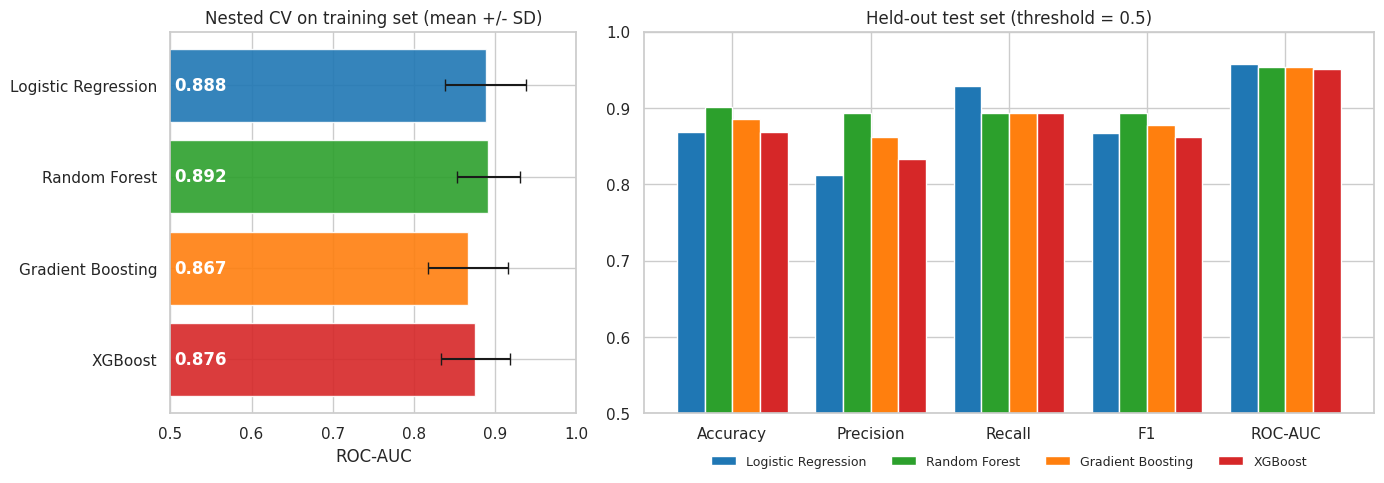

In [6]:
fig = ev.plot_model_comparison(cv_summary, test_metrics)
plt.show()

**Observations - nested CV vs. test set**

* Test performance (ROC-AUC 0.95-0.96, accuracy 0.87-0.90) is **higher than the nested-CV estimate** (ROC-AUC 0.87-0.89, accuracy 0.80-0.83) for every model. The lower ends of the test ROC-AUC intervals (0.89-0.90) sit at or above the cross-validated means (0.87-0.89).
* The most likely explanation is chance: 61 patients form one small sample, and this particular split happens to be somewhat easier than average. The nested-CV figures are based on 15 different validation folds and are the **more conservative and more reliable** estimate of how these models would perform on similar patients: roughly **ROC-AUC 0.88-0.89 and accuracy 0.80-0.83**.
* The important check passes: the test performance is *not* worse than the CV estimate, so there is no sign of over-fitting or leakage in the tuning procedure.

## 3. ROC, precision-recall and calibration curves

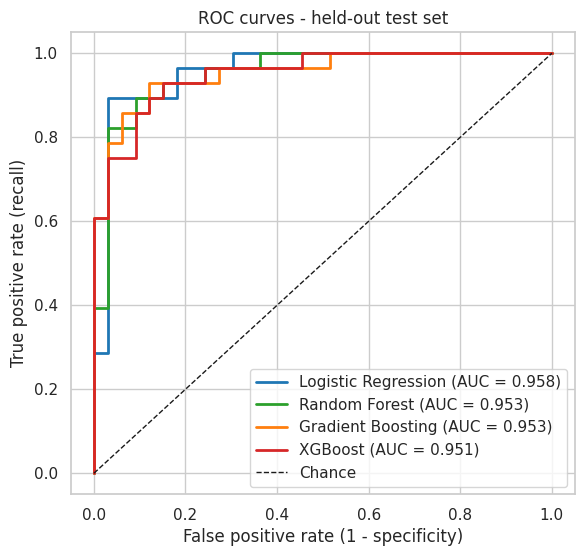

In [7]:
fig = ev.plot_roc_curves(models, X_test, y_test)
plt.show()

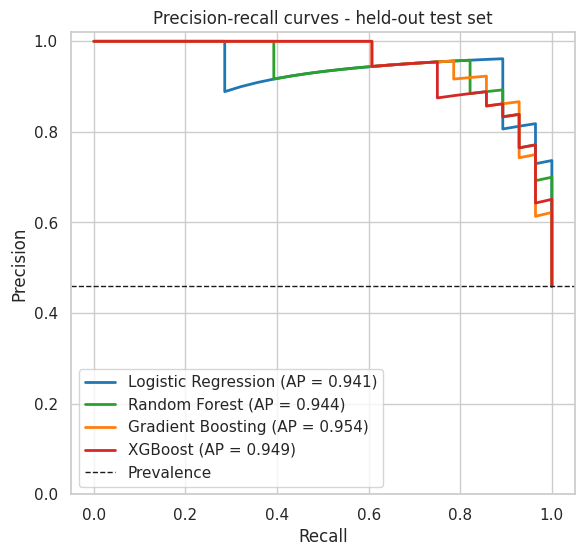

In [8]:
fig = ev.plot_pr_curves(models, X_test, y_test)
plt.show()

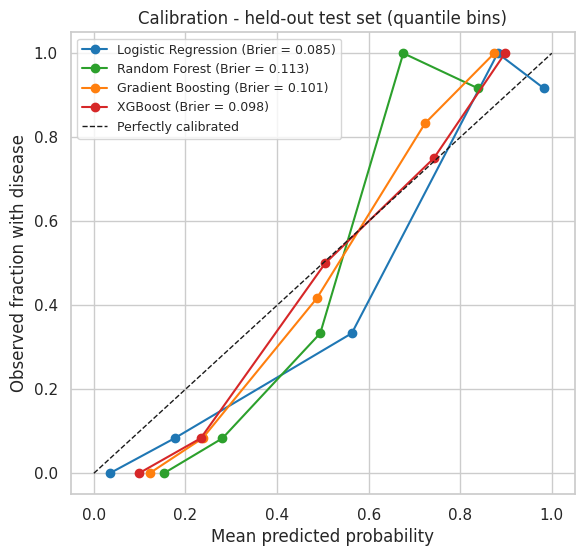

In [9]:
fig = ev.plot_calibration(models, X_test, y_test)
plt.show()

**Observations - ROC, precision-recall and calibration**

* **ROC and precision-recall curves are nearly indistinguishable** across the four models (test ROC-AUC 0.951-0.958; average precision 0.94-0.95 against a disease prevalence of 0.46). All of them rank patients with disease well above patients without.
* **Calibration:** the curves broadly follow the diagonal (higher predicted probability -> more patients with disease), but with about 12 patients per bin they are noisy. In terms of Brier score (lower is better) Logistic Regression is best (0.085), then XGBoost (0.098), Gradient Boosting (0.101) and Random Forest (0.113). The Random Forest is the least well calibrated: its lowest-scoring group (mean predicted probability about 0.15) contained no patient with disease, i.e. its probabilities are less extreme than reality.
* **Consequence for the application:** a model output should be presented as a *model score*, not as the literal probability that a patient has heart disease. Probability calibration (Platt scaling / isotonic regression) is listed as future work.

## 4. Confusion matrices

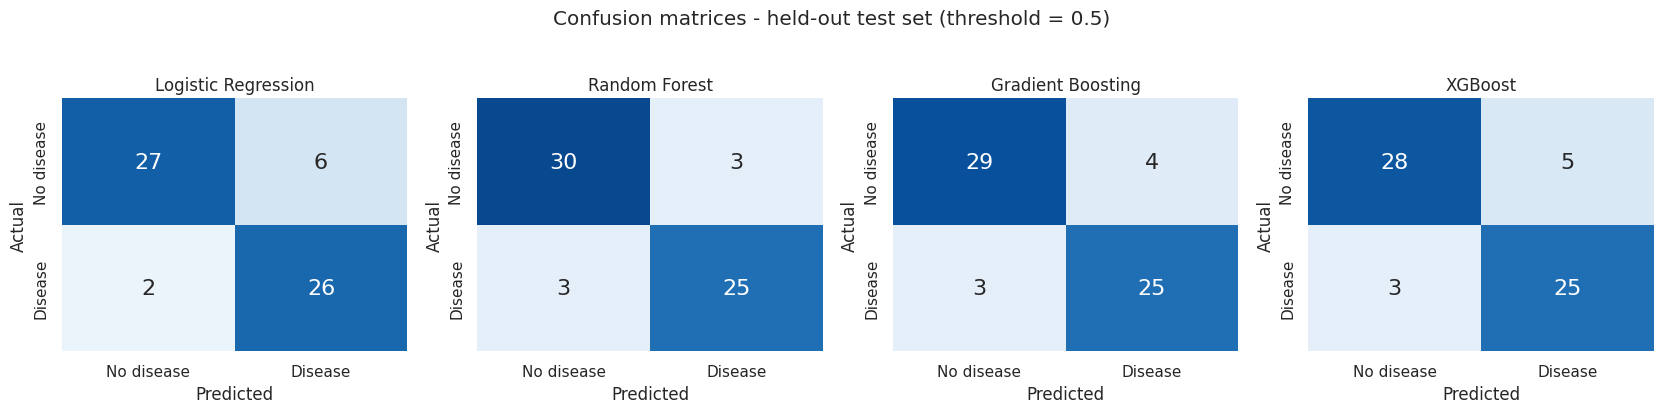

,false negatives (missed disease),false positives (false alarms)
Logistic Regression,2,6
Random Forest,3,3
Gradient Boosting,3,4
XGBoost,3,5


In [10]:
fig = ev.plot_confusion_matrices(models, X_test, y_test)
plt.show()

errors = test_metrics[["fn", "fp"]].astype(int).rename(columns={"fn": "false negatives (missed disease)", "fp": "false positives (false alarms)"})
errors

**Observations - error types**

* Random Forest makes 6 errors (3 false alarms, 3 missed cases); Logistic Regression 8 (6 false alarms, 2 missed); Gradient Boosting 7 (4 / 3); XGBoost 8 (5 / 3).
* Every model misses **2-3 of the 28 patients with disease (7-11 %)** and raises 3-6 false alarms among the 33 healthy patients (9-18 %). Logistic Regression is the most "cautious" (fewest missed cases, most false alarms), Random Forest the most "conservative".
* Which is better depends on how costly a miss is compared with a false alarm - a clinical judgement, not a statistical one. That is exactly why we look at the decision threshold next.

## 5. Decision threshold: trading precision for recall

The 0.5 threshold is a convention, not a law. For screening we may prefer to catch more true cases at the price of more false alarms.

To avoid tuning on the test set, the threshold is studied on **out-of-fold predictions for the training set** (5-fold cross-validated probabilities from the selected model), and only then applied to the test set.

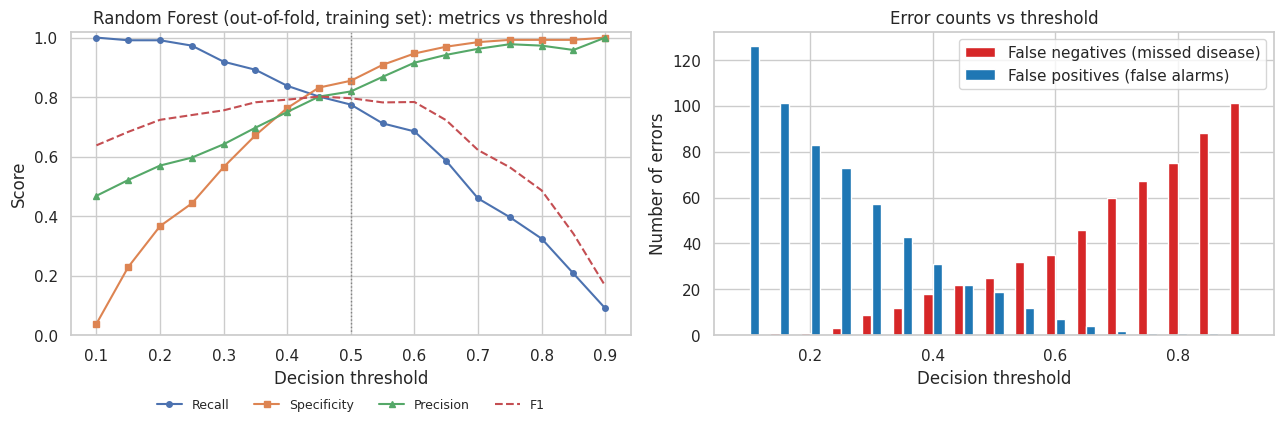

,precision,recall,specificity,f1,fp,fn
threshold,,,,,,
0.25,0.597,0.973,0.443,0.740,73,3
0.30,0.642,0.919,0.565,0.756,57,9
0.35,0.697,0.892,0.672,0.783,43,12
0.40,0.750,0.838,0.763,0.791,31,18
0.45,0.802,0.802,0.832,0.802,22,22
0.50,0.819,0.775,0.855,0.796,19,25
0.55,0.868,0.712,0.908,0.782,12,32
0.60,0.916,0.685,0.947,0.784,7,35


In [11]:
oof = cross_val_predict(
    clone(models[selected]), X_train, y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=pp.RANDOM_STATE), method="predict_proba",
)[:, 1]

fig, oof_tbl = ev.plot_threshold_analysis(y_train, oof, f"{selected} (out-of-fold, training set)")
plt.show()
oof_tbl.loc[[0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]].round(3)

In [12]:
# Highest threshold that still reaches >= 90 % recall on the out-of-fold training predictions
TARGET_RECALL = 0.90
t_screen = oof_tbl.index[oof_tbl["recall"] >= TARGET_RECALL].max()
print(f"Screening threshold chosen on training data (recall >= {TARGET_RECALL:.0%}): {t_screen}")

p_test = models[selected].predict_proba(X_test)[:, 1]
rows = {}
for label, t in [("default 0.50", 0.5), (f"screening {t_screen}", t_screen)]:
    m = ev.compute_metrics(y_test, p_test, t)
    rows[label] = {k: m[k] for k in ["precision", "recall", "specificity", "f1", "fn", "fp"]}
thr_test = pd.DataFrame(rows).T
thr_test[["fn", "fp"]] = thr_test[["fn", "fp"]].astype(int)
thr_test.round(3)

Screening threshold chosen on training data (recall >= 90%): 0.3


,precision,recall,specificity,f1,fn,fp
default 0.50,0.893,0.893,0.909,0.893,3,3
screening 0.3,0.700,1.000,0.636,0.824,0,12


**Observations - threshold trade-off**

* On the training set's out-of-fold predictions, the default 0.5 threshold gives recall 0.775 and precision 0.819. Lowering it to **0.30 raises recall to 0.919** but drops precision to 0.642 and specificity to 0.565; at 0.25 recall is 0.973 but specificity only 0.443 - **there is no free lunch**: every additional case caught costs more false alarms.
* Applying the screening threshold (0.30, the highest threshold with recall >= 90 % on the training data) to the test set removes all 3 missed cases (recall 1.000) but adds 9 false alarms (12 instead of 3). Note that the recall of 1.000 is partly luck of this small test set; the out-of-fold estimate (about 92 % recall with about 57 % specificity) is the more realistic expectation.
* The threshold was chosen **without using the test set**, so this comparison is fair - but which operating point is appropriate is a clinical decision. The Streamlit app could let the user pick between a balanced and a high-sensitivity setting.

## 6. Which features does the selected model use?

*Permutation importance*: shuffle one input feature at a time in the test set and measure how much the ROC-AUC drops. It works on the original 13 features (not the 22 one-hot columns) and applies to any model.

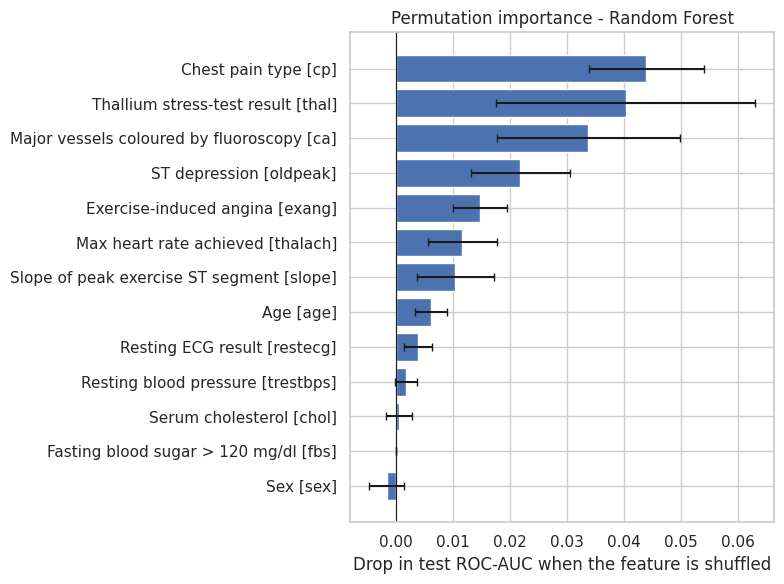

,feature,importance_mean,importance_std
0,cp,0.044,0.010
1,thal,0.040,0.023
2,ca,0.034,0.016
3,oldpeak,0.022,0.009
4,exang,0.015,0.005
5,thalach,0.012,0.006
6,slope,0.010,0.007
7,age,0.006,0.003


In [13]:
fig, imp = ev.plot_feature_importance(models[selected], selected, X_test, y_test)
plt.show()
imp.head(8).round(3)

**Observations - feature importance (permutation, test set)**

* The selected Random Forest relies mostly on **chest-pain type (`cp`), thallium test (`thal`) and number of coloured vessels (`ca`)** (ROC-AUC drops of 0.044, 0.040 and 0.034 when shuffled), followed by ST depression (`oldpeak`, 0.022), exercise-induced angina (`exang`, 0.015), max heart rate (`thalach`, 0.012) and ST slope (`slope`, 0.010).
* This matches the exploratory analysis, where `thal`, `ca`, `cp`, `oldpeak` and `exang` had the strongest associations with the target. `fbs` contributes nothing (as in the EDA), and `chol`, `trestbps`, `restecg` and `sex` contribute almost nothing once the other features are known - `sex` has a large *univariate* difference, but most of its information is apparently carried by other features.
* **Caveats:** the importances come from only 61 patients, and the error bars show variation over shuffles only (not sampling uncertainty). Permutation importance can understate features that are correlated with others (e.g. `oldpeak`, `slope`, `thalach`). It shows what *the model* uses - not what causes disease.

**Next stage:** SHAP will provide a finer view (direction of effect and per-patient explanations).

## 7. Conclusions and limitations

**Main results**

| | Nested CV (242 training patients, 15 folds) | Held-out test (61 patients) |
|---|---|---|
| ROC-AUC, all four models | 0.87 - 0.89 | 0.95 - 0.96 |
| Accuracy, all four models | 0.80 - 0.83 | 0.87 - 0.90 |
| Selected model: Random Forest | ROC-AUC 0.892 +/- 0.039 | ROC-AUC 0.953, accuracy 0.902, recall 0.893, precision 0.893 |

1. Classical machine-learning models predict the presence of heart disease from 13 routine clinical attributes **well above the baseline** (ROC-AUC about 0.89 in cross-validation vs 0.50 for the baseline).
2. **The four models are practically tied.** A regularised logistic regression matches the tree ensembles; the more complex models did not give a measurable gain on 303 patients.
3. The most informative inputs are `cp`, `thal`, `ca`, `oldpeak`, `exang` and `thalach`.
4. With the default threshold, about **one in four (CV) to one in ten (test) patients with disease is missed**; lowering the threshold catches more cases at the price of many more false alarms.

**Limitations (to be stated in the README)**

* Small dataset: 303 patients (61 in the test set), so all estimates carry considerable uncertainty (see the confidence intervals).
* Single-centre, historical data (Cleveland Clinic); 68 % of the patients are men. Results do not necessarily transfer to other populations - no external validation was done.
* The label is angiographic disease status in patients who were referred for testing - not a screening population.
* Predicted scores are not calibrated probabilities.
* Feature importance describes model behaviour, not causation. **This is an educational / research prototype, not a diagnostic tool.**

**Next:** explainability with SHAP (global and per-patient explanations) and the Streamlit application.